In [ ]:
!pip install ROOT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.9/247.9 MB 28.8 MB/s  0:00:08


In [ ]:
import ROOT
import ctypes
import math
import numpy as np

/usr/local/lib/python3.13/dist-packages/ROOT/__init__.py:222: UserWarning: 
This distribution of ROOT is in alpha stage. Feedback is welcome and appreciated. Feel free to reach out to the user forum for questions and general feedback at https://root-forum.cern.ch or to submit an issue at https://github.com/root-project/root/issues. Do not rely on this distribution for production purposes.

  warnings.warn(


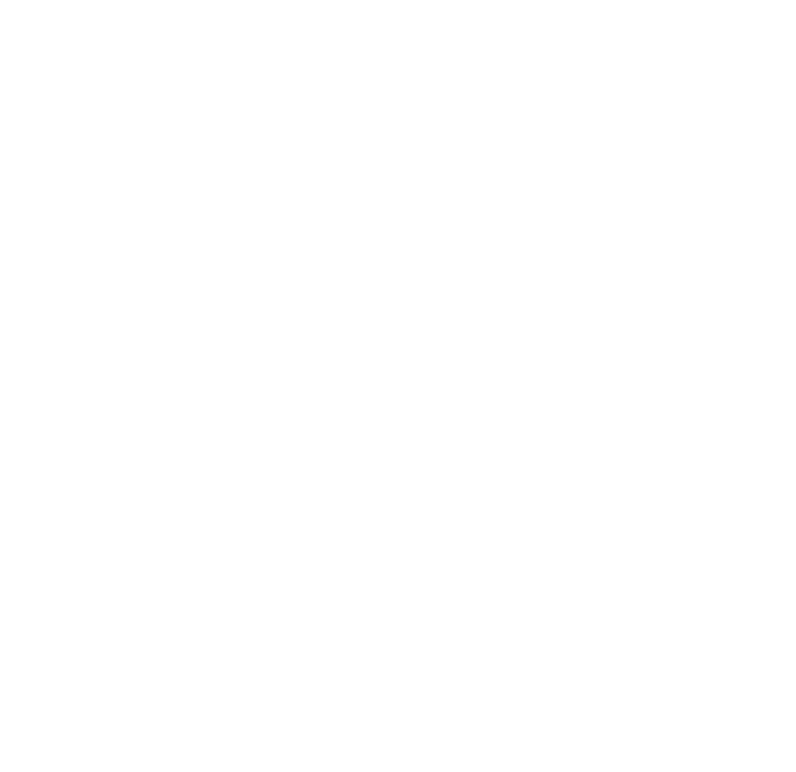

In [ ]:
c=ROOT.TCanvas("c", "c", 800, 800)
hpt1=ROOT.TH1D("hpt1", "H->ZZ*->4#mu;Transverse momentum [Gev/c];counts", 100, 0, 100)
hpt2=ROOT.TH1D("hpt2", "H->ZZ*->4#mu;Transverse momentum [Gev/c];counts", 100, 0, 100)
hpt3=ROOT.TH1D("hpt3", "H->ZZ*->4#mu;Transverse momentum [Gev/c];counts", 100, 0, 100)
hpt4=ROOT.TH1D("hpt4", "H->ZZ*->4#mu;Transverse momentum [Gev/c];counts", 100, 0, 100)

ROOT.gStyle.SetOptStat(0)
hpt1.SetLineColor(ROOT.kRed)
hpt2.SetLineColor(ROOT.kBlue)
hpt3.SetLineColor(ROOT.kGreen)
hpt4.SetLineColor(ROOT.kMagenta)

In [ ]:
mH=125.0
mZ=91.2
mM=0.105


higgsP4=ROOT.TLorentzVector()

higgsP4.SetXYZM(0,0,0,mH)

genH=ROOT.TGenPhaseSpace()
genZ=ROOT.TGenPhaseSpace()
genZstar=ROOT.TGenPhaseSpace()


In [ ]:
h2.Reset()
for i in tqdm.tqdm(range(1000000)):

  mZstar=ROOT.gRandom.Uniform(2*mM,mH-mZ)
  massesZ=np.array([mZ, mZstar], dtype=np.float64)
  genH.SetDecay(higgsP4, 2, massesZ) #H->z+z*

  weightH = genH.Generate()

  ZP4=ROOT.TLorentzVector(genH.GetDecay(0))
  ZstarP4=ROOT.TLorentzVector(genH.GetDecay(1))

  massesM=np.array([mM,mM], dtype=np.float64)
  genZ.SetDecay(ZP4,2, massesM) #Z->mu+mu
  genZstar.SetDecay(ZstarP4,2, massesM)

  weightZ=genZ.Generate()
  weightZstar=genZstar.Generate()
  weight=weightH*weightZ*weightZstar

  p1=genZ.GetDecay(0)
  p2=genZ.GetDecay(1)

  p3=genZstar.GetDecay(0)
  p4=genZstar.GetDecay(1)

  pt = [p1, p2, p3, p4]

  pt.sort(key=lambda x: x.Pt(), reverse=True)

  hpt1.Fill(pt[0].Pt(), weight)
  hpt2.Fill(pt[1].Pt(), weight)
  hpt3.Fill(pt[2].Pt(), weight)
  hpt4.Fill(pt[3].Pt(), weight)
  h2.Fill((p1+p2).M(), (p2+p3).M(), weight)


100%|██████████| 1000000/1000000 [00:45<00:00, 21794.39it/s]


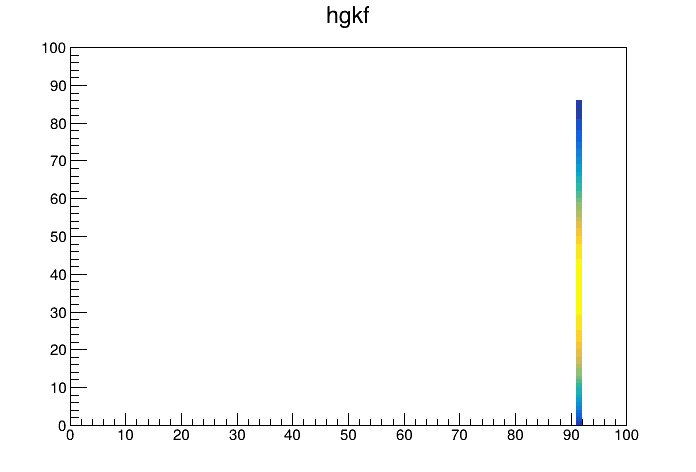

In [ ]:
c3=ROOT.TCanvas("c3", "H")
h2.Draw()
c3.Draw()

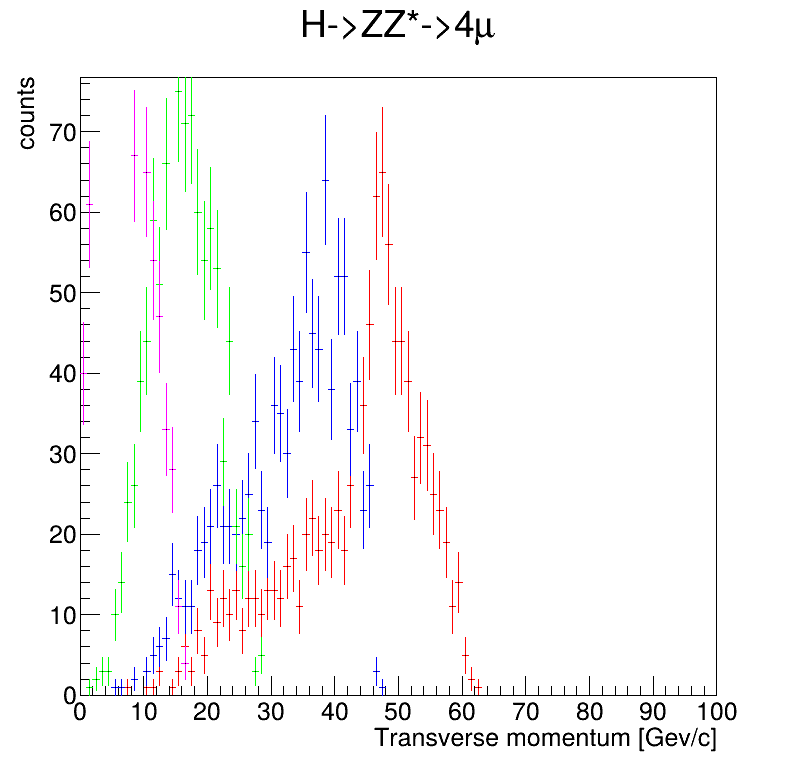

In [ ]:

hpt1.Draw()
hpt2.Draw("same")
hpt3.Draw("same")
hpt4.Draw("same")
c.Draw()

h2=ROOT.TH2D("h2", "hgkf", 100, 0, 100, 100, 0, 100)


In [ ]:
import tqdm


100%|██████████| 1000000/1000000 [00:36<00:00, 27528.94it/s]


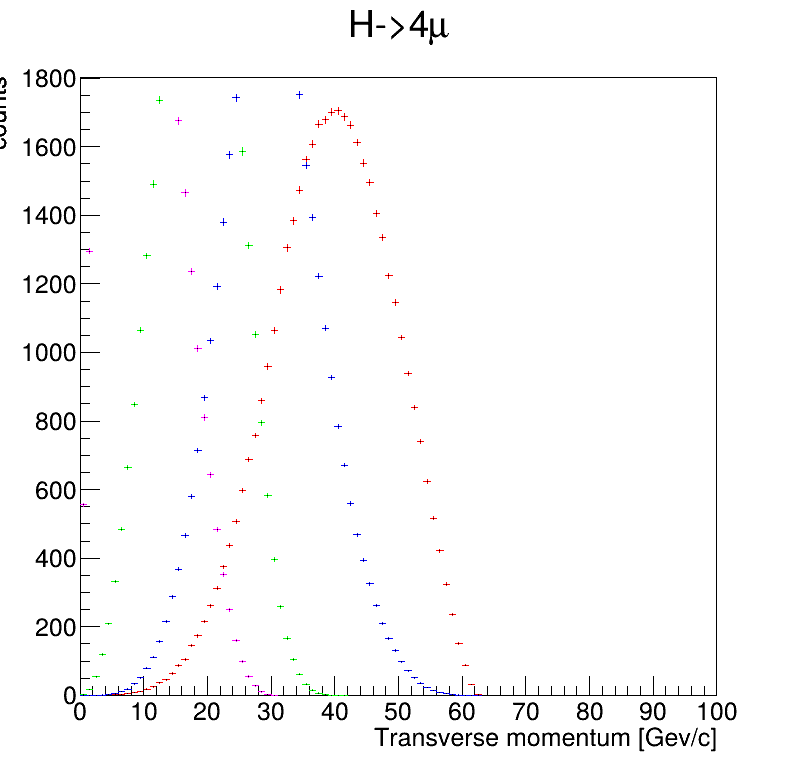

In [ ]:
massesM = np.array([mM, mM, mM, mM], dtype=np.float64)


M4 = genH.SetDecay(higgsP4, 4, massesM)


hpt1.Reset()
hpt2.Reset()
hpt3.Reset()
hpt4.Reset()
hpt1.SetTitle("H->4#mu")
for i in tqdm.tqdm(range(1000000)):
  weight = genH.Generate()
  p1 = ROOT.TLorentzVector(genH.GetDecay(0))
  p2 = ROOT.TLorentzVector(genH.GetDecay(1))
  p3 = ROOT.TLorentzVector(genH.GetDecay(2))
  p4 = ROOT.TLorentzVector(genH.GetDecay(3))

  pt = [p1, p2, p3, p4]
  pt.sort(key=lambda x: x.Pt(), reverse=True)

  hpt1.Fill(pt[0].Pt(), weight)
  hpt2.Fill(pt[1].Pt(), weight)
  hpt3.Fill(pt[2].Pt(), weight)
  hpt4.Fill(pt[3].Pt(), weight)
  h2.Fill((p1+p2).M(), (p2+p3).M(), weight)

hpt1.Draw()
hpt2.Draw("same")
hpt3.Draw("same")
hpt4.Draw("same")

c.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2
Warning in <THistPainter::MakeChopt>: option SCAT is deprecated.


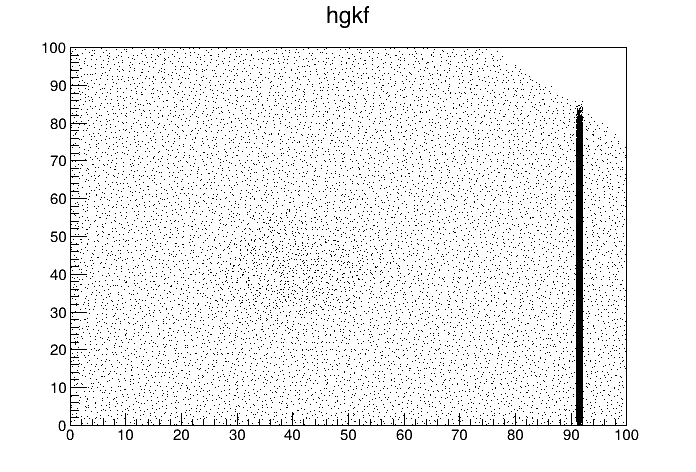

In [ ]:
c2=ROOT.TCanvas("c2", "H2")
h2.Draw("scatter") #cont, LEGO, LEGO2, dalitz plot...
c2.Draw()